Load Libraries

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

# Set display options
pd.set_option("display.max_columns", None)
print("Libraries successfully loaded.")

c:\Users\VIDYA SAGAR\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries successfully loaded.


Load Dataset

In [2]:
# Download and load the IBM Telco Customer Churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Data Cleaning & Preprocessing

In [3]:
# 1. Drop identifier column
df = df.drop(columns=["customerID"])

# 2. Fix 'TotalCharges' column (convert blank strings to numeric NaN and fill with 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 3. Encode Target variable 'Churn' (Yes = 1, No = 0)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Null values remaining:", df.isnull().sum().sum())
print("Target Distribution:")
print(df["Churn"].value_counts(normalize=True))

Null values remaining: 0
Target Distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


Feature Encoding

In [8]:
# Separate Features and Target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Convert categorical columns into dummy variables
X_encoded = pd.get_dummies(X).astype(float)

print(f"Total features after One-Hot Encoding: {X_encoded.shape[1]}")

Total features after One-Hot Encoding: 45


Train/Test split

In [9]:
# Stratified split to maintain balance of churners in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (5634, 45)
Testing set shape: (1409, 45)


Train XGBoost model & Evaluate

In [10]:
# Initialize and train the XGBoost Classifier
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss",
)

model.fit(X_train, y_train)

# Evaluate performance
y_pred_proba = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"=== Model Performance ===")
print(f"ROC-AUC Score: {roc_auc:.4f}\n")
print(classification_report(y_test, model.predict(X_test)))

=== Model Performance ===
ROC-AUC Score: 0.8465

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.68      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



Generate SHAP values & Visualization

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


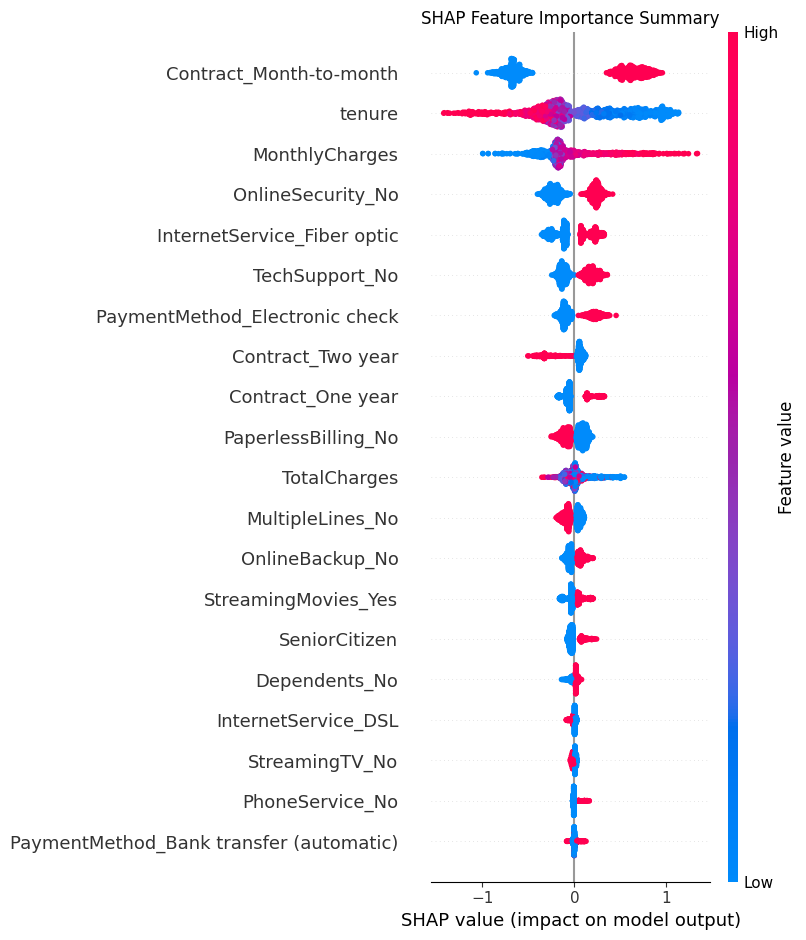

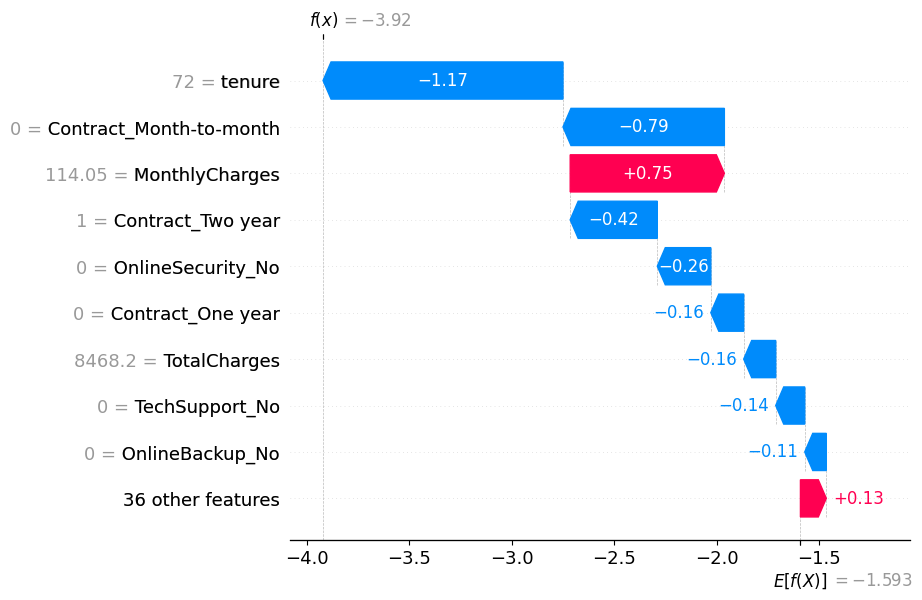

In [11]:
# Initialize SHAP Explainer
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

# Plot overall feature importance summary
plt.title("SHAP Feature Importance Summary")
shap.summary_plot(shap_values, X_test)

# Plot single customer waterfall plot example
plt.figure()
shap.plots.waterfall(shap_values[0])

Save artifacts for Streamlit

In [12]:
# Save model, explainer, and feature column structure to disk
joblib.dump(model, "churn_model.pkl")
joblib.dump(explainer, "explainer.pkl")
joblib.dump(X_train.columns.tolist(), "feature_columns.pkl")

print("All artifacts successfully saved:")
print(" - churn_model.pkl")
print(" - explainer.pkl")
print(" - feature_columns.pkl")

All artifacts successfully saved:
 - churn_model.pkl
 - explainer.pkl
 - feature_columns.pkl
